<a href="https://colab.research.google.com/github/aureliearth/Analisis-Deret-Waktu/blob/main/stasioner_data_ADW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.stattools import adfuller

In [2]:
# Extracting the file ID from the provided Google Drive link
file_id = '1jgPeLoVV8ZrYG4hn-fnZ2muDDCmDpBsT'

# Using the export URL for Google Sheets/Excel stored on Drive
url = f'https://docs.google.com/spreadsheets/d/{file_id}/export?format=xlsx'

try:
    df = pd.read_excel(url)
    print("Dataset loaded successfully!")
    display(df.head())
except Exception as e:
    print("Error loading dataset. Please make sure the file is shared as 'Anyone with the link can view'.")
    print(e)

Dataset loaded successfully!


,Tanggal,Sales Invoice,Customer,Branch,Item Code,Item Name,Sub Brand,Qty,Harga,Total Harga,Retur,Diskon,Total
0,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,8010101021*,Color Chart Zillenial Colour System New ( 5 po...,ShowMeMore,1,750000,750000,0,0,750000
1,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010209051,IL VASTO Pearl Hair Cream Colorant 12.12 Blond...,Classico Vegan,6,109000,654000,0,0,654000
2,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,12,116000,1392000,0,0,1392000
3,2026-03-01,ACC-SINV-2026-05722,Salon mode- Banjarmasin,BJM,1050202011,SLEEK ET LISSE Step 1 Strong Curly Hair 500 Ml,Straight System,3,159000,477000,0,0,477000
4,2026-03-01,ACC-SINV-2026-05723,ZIZE SALON - MEDAN,MDN,1010211011,IL VASTO Zicos Hair Cream Colorant Champagne 1...,Zicos Vegan,1,116000,116000,0,0,116000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34563 entries, 0 to 34562
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Tanggal        34562 non-null  datetime64[ns]
 1   Sales Invoice  34562 non-null  object        
 2   Customer       34562 non-null  object        
 3   Branch         34562 non-null  object        
 4   Item Code      34562 non-null  object        
 5   Item Name      34562 non-null  object        
 6   Sub Brand      34562 non-null  object        
 7   Qty            34563 non-null  int64         
 8   Harga          34563 non-null  int64         
 9   Total Harga    34563 non-null  int64         
 10  Retur          34563 non-null  int64         
 11  Diskon         34563 non-null  int64         
 12  Total          34563 non-null  int64         
dtypes: datetime64[ns](1), int64(6), object(6)
memory usage: 3.4+ MB


In [17]:
# Drop all columns with 'object' data type
df = df.select_dtypes(exclude=['object'])

# Display the updated dataframe information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34563 entries, 0 to 34562
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Tanggal      34562 non-null  datetime64[ns]
 1   Qty          34563 non-null  int64         
 2   Harga        34563 non-null  int64         
 3   Total Harga  34563 non-null  int64         
 4   Retur        34563 non-null  int64         
 5   Diskon       34563 non-null  int64         
 6   Total        34563 non-null  int64         
dtypes: datetime64[ns](1), int64(6)
memory usage: 1.8 MB


In [24]:
# Mengubah format tanggal
df['Tanggal'] = pd.to_datetime(df['Tanggal'], errors='coerce')

# Menghapus baris tanpa tanggal
df = df.dropna(subset=['Tanggal'])

# Agregasi penjualan harian
data_harian = df.groupby('Tanggal')['Total'].sum()

# Melengkapi tanggal yang tidak memiliki transaksi
data_harian = data_harian.asfreq('D', fill_value=0)

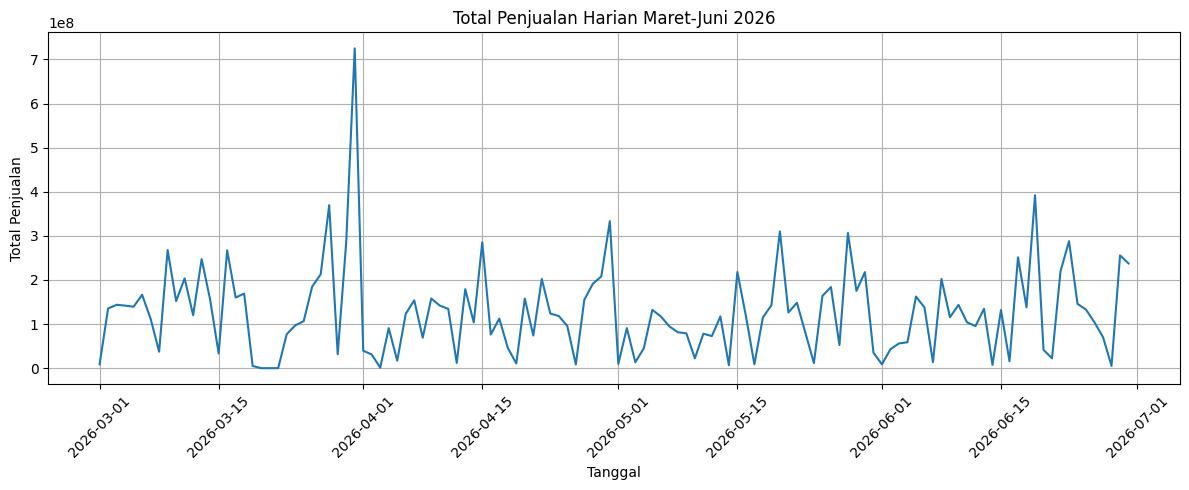

In [25]:
plt.figure(figsize=(12, 5))
plt.plot(data_harian.index, data_harian.values)

plt.title('Total Penjualan Harian Maret-Juni 2026')
plt.xlabel('Tanggal')
plt.ylabel('Total Penjualan')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
from statsmodels.tsa.stattools import adfuller, kpss

hasil_adf = adfuller(data_harian, autolag='AIC')

print("ADF Statistic:", hasil_adf[0])
print("p-value:", hasil_adf[1])
if hasil_adf[1] < 0.05:
        print("\nKesimpulan: Data STASIONER")
else:
        print("\nKesimpulan: Data BELUM STASIONER")

hasil_kpss = kpss(data_harian, regression='c', nlags='auto')

print("\n KPSS Statistic:", hasil_kpss[0])
print("p-value:", hasil_kpss[1])

ADF Statistic: -10.079375575824255
p-value: 1.1998518989513219e-17

Kesimpulan: Data STASIONER

 KPSS Statistic: 0.062258737473189066
p-value: 0.1


/tmp/ipykernel_368/2253136159.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  hasil_kpss = kpss(data_harian, regression='c', nlags='auto')
